# Breast Cancer Classification using AdaBoost

In [1]:

# Data Handling
import os
import glob
import numpy as np
import pandas as pd

# Image Processing
import cv2
from skimage.feature import hog
from skimage.color import rgb2gray

# Machine Learning
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GroupShuffleSplit

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Model Saving
import joblib

# Reproducibility
np.random.seed(42)

print("All libraries imported successfully!")


All libraries imported successfully!


# Load Breast Cancer Histopathology Dataset

In [2]:

import os
import glob
import numpy as np

# Dataset path
dataset_path = r"C:\Users\utkri\Downloads\archive (2)\IDC_regular_ps50_idx5"

# Initialize lists
image_paths = []
labels = []
patient_ids = []

# Load dataset
for patient_folder in os.listdir(dataset_path):

    patient_path = os.path.join(dataset_path, patient_folder)

    if not os.path.isdir(patient_path):
        continue

    for label_folder in ["0", "1"]:

        class_path = os.path.join(patient_path, label_folder)

        if os.path.exists(class_path):

            images = glob.glob(
                os.path.join(class_path, "*.png")
            )

            for img_path in images:
                image_paths.append(img_path)
                labels.append(int(label_folder))
                patient_ids.append(patient_folder)

# Convert lists into NumPy arrays
image_paths = np.array(image_paths)
labels = np.array(labels)
patient_ids = np.array(patient_ids)

# Dataset summary
print("========== DATASET LOADED SUCCESSFULLY ==========")

print("Total Images:", len(image_paths))
print("Non-Cancerous Images:", np.sum(labels == 0))
print("Cancerous Images:", np.sum(labels == 1))
print("Total Patients:", len(np.unique(patient_ids)))


========== DATASET LOADED SUCCESSFULLY ==========
Total Images: 277524
Non-Cancerous Images: 198738
Cancerous Images: 78786
Total Patients: 279


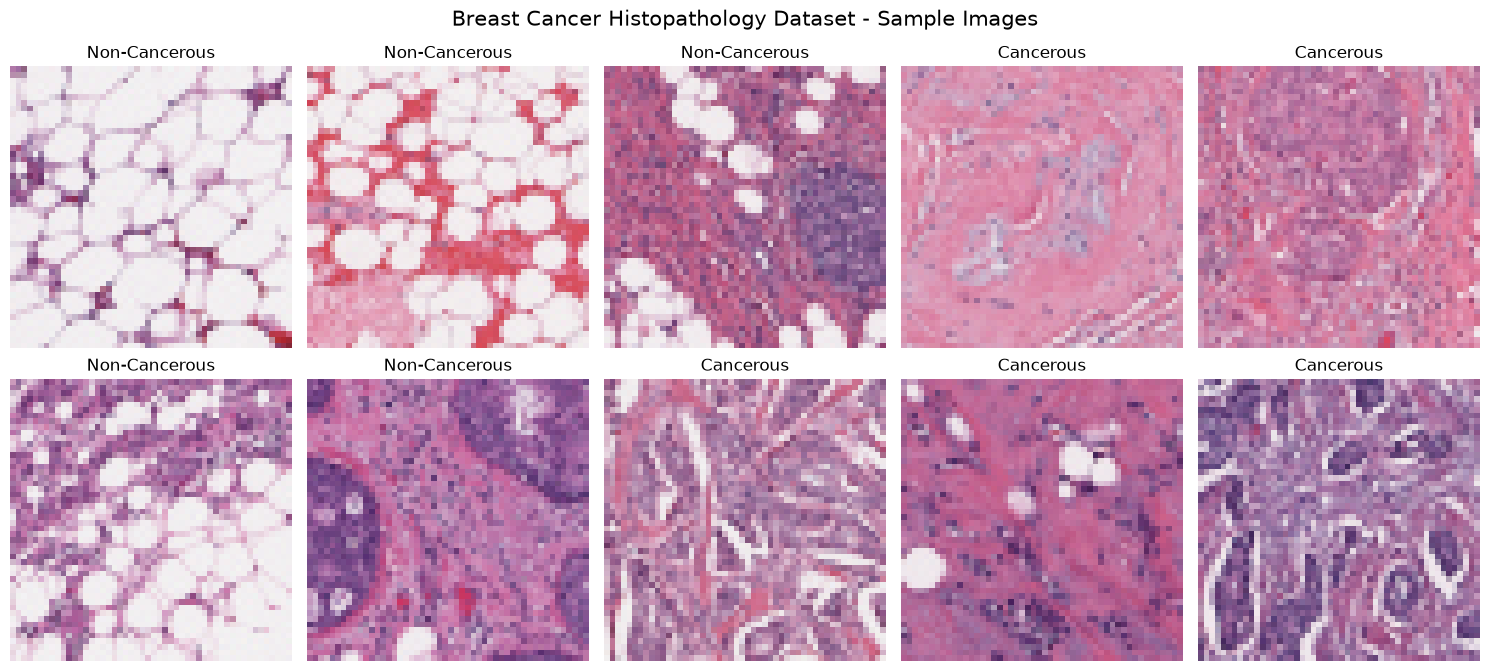

In [3]:

import matplotlib.pyplot as plt
import cv2
import numpy as np

# Select 10 random images
indices = np.random.choice(
    len(image_paths),
    10,
    replace=False
)

plt.figure(figsize=(15, 7))

for i, idx in enumerate(indices):

    # Read image
    img = cv2.imread(image_paths[idx])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)

    # Assign class label
    label = "Cancerous" if labels[idx] == 1 else "Non-Cancerous"

    plt.title(label)
    plt.axis("off")

plt.suptitle(
    "Breast Cancer Histopathology Dataset - Sample Images",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [4]:
from sklearn.model_selection import GroupShuffleSplit

# First split: 80% training pool, 20% testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(image_paths, labels, groups=patient_ids)
)

X_train_paths_all = image_paths[train_idx]
y_train_all = labels[train_idx]
groups_train_all = patient_ids[train_idx]

X_test_paths = image_paths[test_idx]
y_test = labels[test_idx]
groups_test = patient_ids[test_idx]

# Second split: 15% validation from training pool
splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_sub_idx, val_idx = next(
    splitter_val.split(
        X_train_paths_all,
        y_train_all,
        groups=groups_train_all
    )
)

X_train_paths = X_train_paths_all[train_sub_idx]
y_train = y_train_all[train_sub_idx]
groups_train = groups_train_all[train_sub_idx]

X_val_paths = X_train_paths_all[val_idx]
y_val = y_train_all[val_idx]
groups_val = groups_train_all[val_idx]

# Check patient overlap
train_patients = set(groups_train)
val_patients = set(groups_val)
test_patients = set(groups_test)

print("========== DATA SPLITTING RESULTS ==========")

print("Training Images:", len(X_train_paths))
print("Validation Images:", len(X_val_paths))
print("Testing Images:", len(X_test_paths))

print("\nTraining Patients:", len(train_patients))
print("Validation Patients:", len(val_patients))
print("Testing Patients:", len(test_patients))

print("\n========== PATIENT OVERLAP CHECK ==========")

print("Train & Validation:", len(train_patients & val_patients))
print("Train & Test:", len(train_patients & test_patients))
print("Validation & Test:", len(val_patients & test_patients))

========== DATA SPLITTING RESULTS ==========
Training Images: 181549
Validation Images: 38484
Testing Images: 57491

Training Patients: 189
Validation Patients: 34
Testing Patients: 56

========== PATIENT OVERLAP CHECK ==========
Train & Validation: 0
Train & Test: 0
Validation & Test: 0


In [5]:
def create_balanced_subset(paths, labels, samples_per_class, seed=42):

    rng = np.random.RandomState(seed)
    selected_indices = []

    for class_label in [0, 1]:

        class_indices = np.where(labels == class_label)[0]

        if len(class_indices) < samples_per_class:
            raise ValueError(
                f"Not enough samples for class {class_label}"
            )

        chosen = rng.choice(
            class_indices,
            size=samples_per_class,
            replace=False
        )

        selected_indices.extend(chosen)

    selected_indices = np.array(selected_indices)
    rng.shuffle(selected_indices)

    return paths[selected_indices], labels[selected_indices]


# Balanced training dataset
X_train_balanced, y_train_balanced = create_balanced_subset(
    X_train_paths, y_train, 2000
)

# Balanced validation dataset
X_val, y_val = create_balanced_subset(
    X_val_paths, y_val, 1000
)

# Balanced testing dataset
X_test_sample, y_test_sample = create_balanced_subset(
    X_test_paths, y_test, 1000
)


# Display dataset information
print("========== BALANCED DATASET ==========")

print("Training Images:", len(X_train_balanced))
print("Training Class 0:", np.sum(y_train_balanced == 0))
print("Training Class 1:", np.sum(y_train_balanced == 1))

print("\nValidation Images:", len(X_val))
print("Validation Class 0:", np.sum(y_val == 0))
print("Validation Class 1:", np.sum(y_val == 1))

print("\nTesting Images:", len(X_test_sample))
print("Testing Class 0:", np.sum(y_test_sample == 0))
print("Testing Class 1:", np.sum(y_test_sample == 1))

========== BALANCED DATASET ==========
Training Images: 4000
Training Class 0: 2000
Training Class 1: 2000

Validation Images: 2000
Validation Class 0: 1000
Validation Class 1: 1000

Testing Images: 2000
Testing Class 0: 1000
Testing Class 1: 1000


In [6]:
from skimage.feature import hog
from skimage.color import rgb2gray
import cv2
import numpy as np

def extract_hog_features(image_paths):

    features = []

    for i, img_path in enumerate(image_paths):

        # Read image
        img = cv2.imread(img_path)

        # Convert BGR to RGB
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Resize image
        img = cv2.resize(img, (64, 64))

        # Convert RGB to grayscale
        gray = rgb2gray(img)

        # Extract HOG features
        hog_features = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        features.append(hog_features)

        if (i + 1) % 500 == 0:
            print(f"Processed {i + 1}/{len(image_paths)} images")

    return np.array(features)


# Extract training features
print("Extracting Training HOG Features...")
X_train_features = extract_hog_features(X_train_balanced)

# Extract validation features
print("\nExtracting Validation HOG Features...")
X_val_features = extract_hog_features(X_val)

# Extract testing features
print("\nExtracting Testing HOG Features...")
X_test_features = extract_hog_features(X_test_sample)

print("\n========== HOG FEATURE EXTRACTION COMPLETED ==========")

print("Training Shape:", X_train_features.shape)
print("Validation Shape:", X_val_features.shape)
print("Testing Shape:", X_test_features.shape)

Extracting Training HOG Features...
Processed 500/4000 images
Processed 1000/4000 images
Processed 1500/4000 images
Processed 2000/4000 images
Processed 2500/4000 images
Processed 3000/4000 images
Processed 3500/4000 images
Processed 4000/4000 images

Extracting Validation HOG Features...
Processed 500/2000 images
Processed 1000/2000 images
Processed 1500/2000 images
Processed 2000/2000 images

Extracting Testing HOG Features...
Processed 500/2000 images
Processed 1000/2000 images
Processed 1500/2000 images
Processed 2000/2000 images

========== HOG FEATURE EXTRACTION COMPLETED ==========
Training Shape: (4000, 1764)
Validation Shape: (2000, 1764)
Testing Shape: (2000, 1764)


In [7]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Hyperparameter combinations
n_estimators_list = [50, 100, 150, 200]
learning_rates = [0.01, 0.1, 0.5, 1.0]

results = []

best_f1 = 0
best_ada_model = None
best_params = None

print("========== ADABOOST HYPERPARAMETER TUNING ==========")

for n in n_estimators_list:

    for lr in learning_rates:

        # Initialize AdaBoost
        ada_model = AdaBoostClassifier(
            n_estimators=n,
            learning_rate=lr,
            random_state=42
        )

        # Train model
        ada_model.fit(
            X_train_features,
            y_train_balanced
        )

        # Validation prediction
        y_val_pred = ada_model.predict(X_val_features)

        # Evaluation
        accuracy = accuracy_score(y_val, y_val_pred)
        precision = precision_score(y_val, y_val_pred, zero_division=0)
        recall = recall_score(y_val, y_val_pred, zero_division=0)
        f1 = f1_score(y_val, y_val_pred, zero_division=0)

        results.append({
            "N Estimators": n,
            "Learning Rate": lr,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1
        })

        print(
            f"Estimators: {n}, Learning Rate: {lr} | "
            f"Accuracy: {accuracy:.4f} | "
            f"F1 Score: {f1:.4f}"
        )

        # Select best model using validation F1
        if f1 > best_f1:
            best_f1 = f1
            best_ada_model = ada_model
            best_params = {
                "n_estimators": n,
                "learning_rate": lr
            }

# Results DataFrame
ada_results = pd.DataFrame(results)

print("\n========== BEST ADABOOST MODEL ==========")
print("Best Parameters:", best_params)
print("Best Validation F1-Score:", round(best_f1, 4))

ada_results

========== ADABOOST HYPERPARAMETER TUNING ==========
Estimators: 50, Learning Rate: 0.01 | Accuracy: 0.5315 | F1 Score: 0.6739
Estimators: 50, Learning Rate: 0.1 | Accuracy: 0.5715 | F1 Score: 0.6723
Estimators: 50, Learning Rate: 0.5 | Accuracy: 0.6090 | F1 Score: 0.6612
Estimators: 50, Learning Rate: 1.0 | Accuracy: 0.6205 | F1 Score: 0.6491
Estimators: 100, Learning Rate: 0.01 | Accuracy: 0.5385 | F1 Score: 0.6765
Estimators: 100, Learning Rate: 0.1 | Accuracy: 0.5815 | F1 Score: 0.6734
Estimators: 100, Learning Rate: 0.5 | Accuracy: 0.6195 | F1 Score: 0.6619
Estimators: 100, Learning Rate: 1.0 | Accuracy: 0.6290 | F1 Score: 0.6487
Estimators: 150, Learning Rate: 0.01 | Accuracy: 0.5460 | F1 Score: 0.6792
Estimators: 150, Learning Rate: 0.1 | Accuracy: 0.5985 | F1 Score: 0.6636
Estimators: 150, Learning Rate: 0.5 | Accuracy: 0.6235 | F1 Score: 0.6563
Estimators: 150, Learning Rate: 1.0 | Accuracy: 0.6235 | F1 Score: 0.6483
Estimators: 200, Learning Rate: 0.01 | Accuracy: 0.5525 | F1

,N Estimators,Learning Rate,Accuracy,Precision,Recall,F1 Score
0,50,0.01,0.5315,0.516818,0.968,0.673860
1,50,0.10,0.5715,0.544272,0.879,0.672275
2,50,0.50,0.6090,0.583333,0.763,0.661179
3,50,1.00,0.6205,0.603611,0.702,0.649098
4,100,0.01,0.5385,0.520777,0.965,0.676481
5,100,0.10,0.5815,0.552143,0.863,0.673430
6,100,0.50,0.6195,0.595524,0.745,0.661928
7,100,1.00,0.6290,0.616007,0.685,0.648674
8,150,0.01,0.5460,0.525137,0.961,0.679152
9,150,0.10,0.5985,0.571017,0.792,0.663594


# Hyperparameter Comparison Visualization

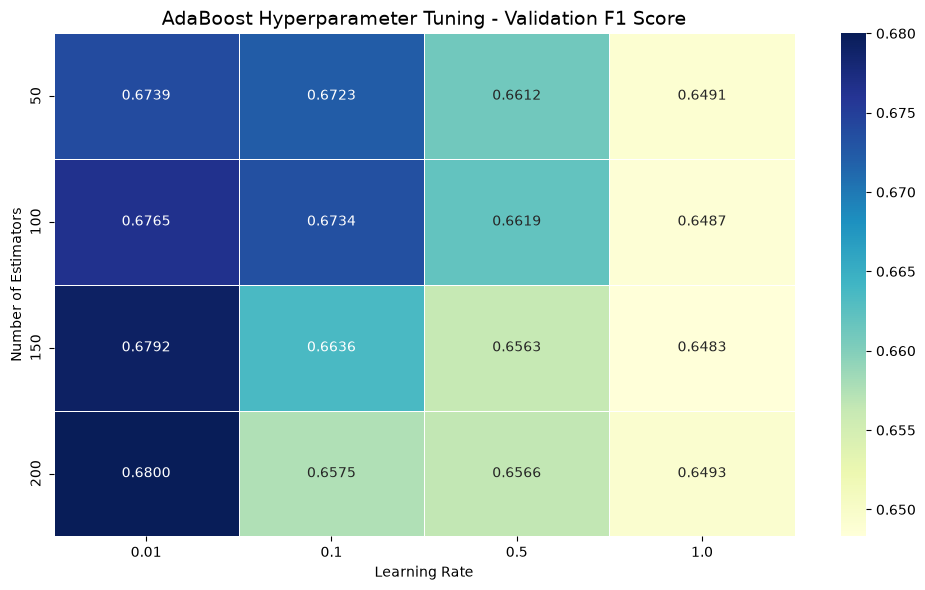

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create pivot table
f1_pivot = ada_results.pivot(
    index="N Estimators",
    columns="Learning Rate",
    values="F1 Score"
)

# Plot heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    f1_pivot,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title(
    "AdaBoost Hyperparameter Tuning - Validation F1 Score",
    fontsize=14
)

plt.xlabel("Learning Rate")
plt.ylabel("Number of Estimators")

plt.tight_layout()
plt.show()

# Accuracy vs F1-Score

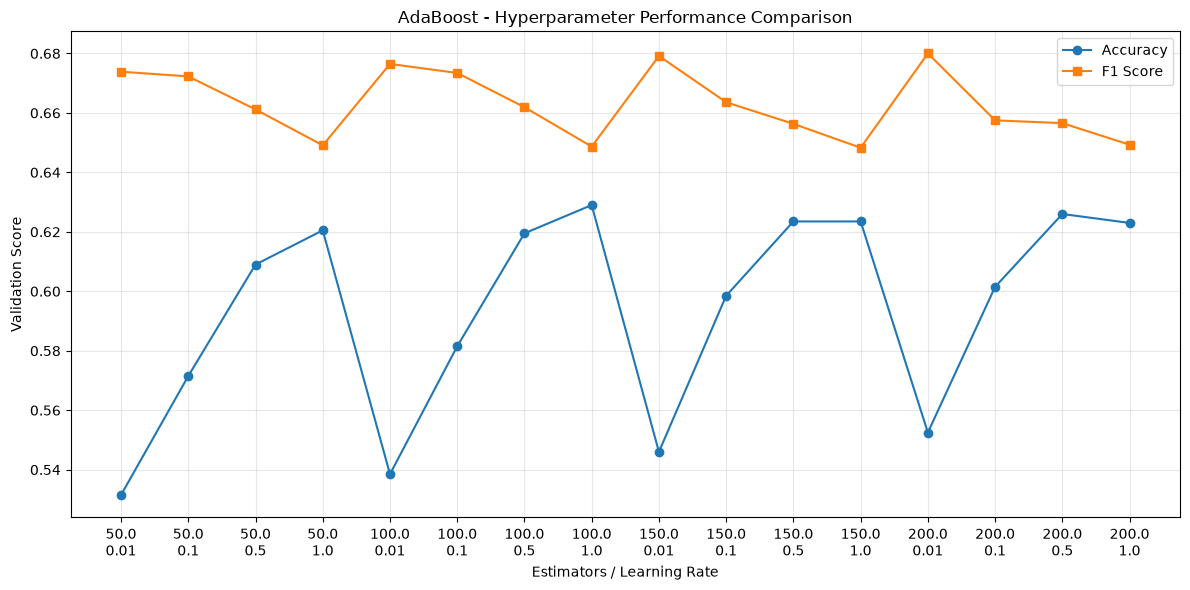

In [9]:
plt.figure(figsize=(12, 6))

x = range(len(ada_results))

plt.plot(
    x,
    ada_results["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    x,
    ada_results["F1 Score"],
    marker="s",
    label="F1 Score"
)

plt.xticks(
    x,
    [
        f'{row["N Estimators"]}\n{row["Learning Rate"]}'
        for _, row in ada_results.iterrows()
    ]
)

plt.xlabel("Estimators / Learning Rate")
plt.ylabel("Validation Score")
plt.title("AdaBoost - Hyperparameter Performance Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Use the best model selected during validation
final_ada_model = best_ada_model

# Predict test labels
y_test_pred = final_ada_model.predict(X_test_features)

# Predict probabilities for ROC-AUC
y_test_prob = final_ada_model.predict_proba(X_test_features)[:, 1]

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test_sample, y_test_pred)

test_precision = precision_score(
    y_test_sample, y_test_pred, zero_division=0
)

test_recall = recall_score(
    y_test_sample, y_test_pred, zero_division=0
)

test_f1 = f1_score(
    y_test_sample, y_test_pred, zero_division=0
)

test_roc_auc = roc_auc_score(
    y_test_sample, y_test_prob
)

# Display results
print("========== FINAL ADABOOST MODEL PERFORMANCE ==========")

print("Best Parameters:", best_params)

print("\nTest Accuracy:", round(test_accuracy, 4))
print("Test Precision:", round(test_precision, 4))
print("Test Recall:", round(test_recall, 4))
print("Test F1-Score:", round(test_f1, 4))
print("Test ROC-AUC Score:", round(test_roc_auc, 4))

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test_sample,
        y_test_pred,
        target_names=["Non-Cancerous", "Cancerous"],
        zero_division=0
    )
)

========== FINAL ADABOOST MODEL PERFORMANCE ==========
Best Parameters: {'n_estimators': 200, 'learning_rate': 0.01}

Test Accuracy: 0.5715
Test Precision: 0.5395
Test Recall: 0.977
Test F1-Score: 0.6951
Test ROC-AUC Score: 0.6981

========== CLASSIFICATION REPORT ==========
               precision    recall  f1-score   support

Non-Cancerous       0.88      0.17      0.28      1000
    Cancerous       0.54      0.98      0.70      1000

     accuracy                           0.57      2000
    macro avg       0.71      0.57      0.49      2000
 weighted avg       0.71      0.57      0.49      2000



# Confusion Matrix & ROC Curve Visualization.

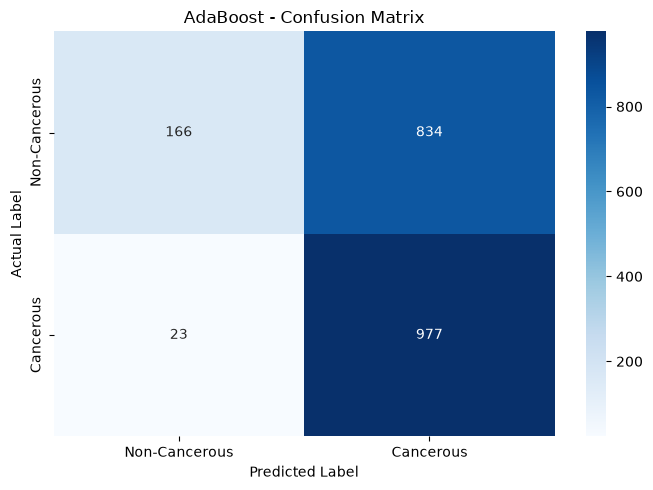

In [11]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix
cm = confusion_matrix(y_test_sample, y_test_pred)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Cancerous", "Cancerous"],
    yticklabels=["Non-Cancerous", "Cancerous"]
)

plt.title("AdaBoost - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

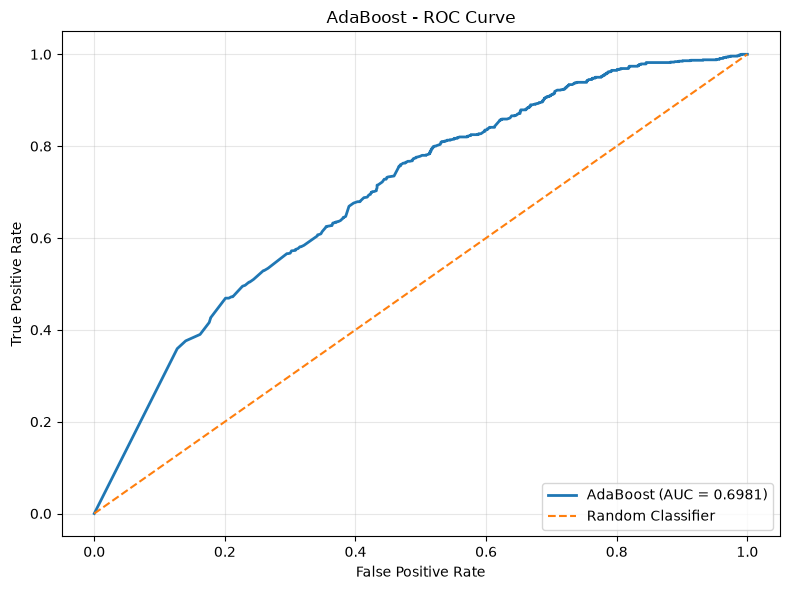

In [12]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(
    y_test_sample,
    y_test_prob
)

roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"AdaBoost (AUC = {roc_auc:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("AdaBoost - ROC Curve")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

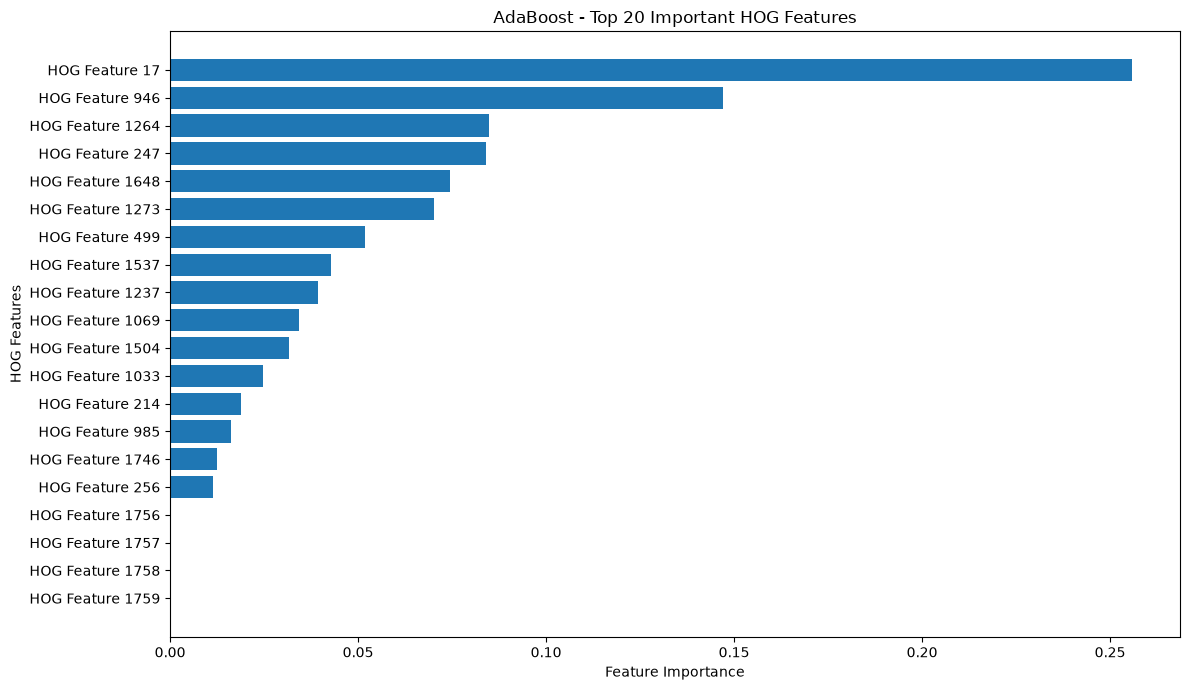

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
feature_importance = final_ada_model.feature_importances_

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": [
        f"HOG Feature {i}" for i in range(len(feature_importance))
    ],
    "Importance": feature_importance
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Select top 20 features
top_20 = importance_df.head(20)

# Plot
plt.figure(figsize=(12, 7))

plt.barh(
    top_20["Feature"][::-1],
    top_20["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("HOG Features")
plt.title("AdaBoost - Top 20 Important HOG Features")

plt.tight_layout()
plt.show()

In [14]:
importance_df.to_csv(
    "adaboost_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


# Trained AdaBoost Model

In [15]:
import joblib

# Save trained model
joblib.dump(
    final_ada_model,
    "best_adaboost_model.pkl"
)

# Save hyperparameter results
ada_results.to_csv(
    "adaboost_hyperparameter_results.csv",
    index=False
)

# Save final performance metrics
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_roc_auc
    ]
})

final_results.to_csv(
    "adaboost_final_results.csv",
    index=False
)

print("========== FILES SAVED SUCCESSFULLY ==========")
print("1. best_adaboost_model.pkl")
print("2. adaboost_hyperparameter_results.csv")
print("3. adaboost_feature_importance.csv")
print("4. adaboost_final_results.csv")

========== FILES SAVED SUCCESSFULLY ==========
1. best_adaboost_model.pkl
2. adaboost_hyperparameter_results.csv
3. adaboost_feature_importance.csv
4. adaboost_final_results.csv


In [16]:
print("=" * 60)
print("              ADABOOST EXPERIMENT CONCLUSION")
print("=" * 60)

print("""
In this experiment, the AdaBoost ensemble learning algorithm
was implemented for breast cancer histopathology image
classification using the IDC dataset.

HOG (Histogram of Oriented Gradients) was used for feature
extraction, followed by patient-wise dataset splitting to
reduce data leakage.

Multiple hyperparameter combinations were evaluated using
validation F1-score. The best configuration was selected
and evaluated on the independent test dataset.
""")

print("BEST HYPERPARAMETERS")
print("--------------------")
print("Number of Estimators:", best_params["n_estimators"])
print("Learning Rate:", best_params["learning_rate"])

print("\nFINAL TEST PERFORMANCE")
print("----------------------")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_roc_auc:.4f}")

print("""
The experiment demonstrates the application of ensemble
learning with HOG-based image features for histopathology
image classification.

This implementation is intended for research and educational
purposes and is not a clinical diagnostic system.
""")

print("=" * 60)

              ADABOOST EXPERIMENT CONCLUSION

In this experiment, the AdaBoost ensemble learning algorithm
was implemented for breast cancer histopathology image
classification using the IDC dataset.

HOG (Histogram of Oriented Gradients) was used for feature
extraction, followed by patient-wise dataset splitting to
reduce data leakage.

Multiple hyperparameter combinations were evaluated using
validation F1-score. The best configuration was selected
and evaluated on the independent test dataset.

BEST HYPERPARAMETERS
--------------------
Number of Estimators: 200
Learning Rate: 0.01

FINAL TEST PERFORMANCE
----------------------
Accuracy:  0.5715
Precision: 0.5395
Recall:    0.9770
F1-Score:  0.6951
ROC-AUC:   0.6981

The experiment demonstrates the application of ensemble
learning with HOG-based image features for histopathology
image classification.

This implementation is intended for research and educational
purposes and is not a clinical diagnostic system.

